# 01 - Standard Datasheet Curves Extraction (IRFS7730PBF)

Extracts and plots the datasheet studies from the vendor SPICE model
`SpiceModels/irfs7730pbf.spi` (subcircuit `irfb_s_sl7730pbf`, pins 1=Drain, 2=Gate, 3=Source):

| # | Study | Source |
|---|---|---|
| 1 | Output Characteristics - Id vs Vds family | `StaticSweepTestbench.run_output_characteristics` |
| 2 | Transfer Characteristic - Id vs Vgs | `StaticSweepTestbench.run_transfer_characteristics` |
| 3 | On-State Resistance - Rds(on) vs Id | `StaticSweepTestbench.run_rds_on` |
| 4 | Capacitances - Ciss/Coss/Crss vs Vds | `CapacitanceTestbench.run` |
| 5 | Gate Charge (quasi-static) - Vgs vs Qg | `gate_charge.reconstruct_gate_charge` + Curves 2 & 4 |
| 6 | Body Diode - Isd vs Vsd | `StaticSweepTestbench.run_body_diode` |
| 7 | Gate Threshold Voltage - Vgs(th) @ Id=250uA | `StaticSweepTestbench.run_threshold_voltage` |

**Gate charge note**: the raw constant-current transient is blocked on this vendor model by the
MODPEX sense-and-mirror pathology (`gate_charge_error_analysis.md`). Curve 5 is instead
**reconstructed quasi-statically** from the validated transfer and capacitance data using the
standard three-segment model (Qgs / Miller plateau Qgd / tail).

Style: publication-quality serif/STIX typography, boxed axes with inward minor ticks on all four
sides, subtle dashed grid, engineering-unit tick labels, 300 dpi, EAST-outside legend with the
figure space reserved automatically via constrained layout. Plots are displayed inline.


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from common.plotting import setup_style, plot_curves
from simulation.testbenches.static_sweep import StaticSweepTestbench
from simulation.testbenches.capacitance import CapacitanceTestbench
from simulation.testbenches.gate_charge import reconstruct_gate_charge, plot_gate_charge

LIB = Path("../SpiceModels/irfs7730pbf.spi").resolve()
SUBCKT = "irfb_s_sl7730pbf"
TITLE = "IRFS7730PBF"

setup_style()
static = StaticSweepTestbench()


## Study 1 - Output Characteristics (Id vs Vds family)
Datasheet gate curves: Vgs = 4.5 / 5 / 6 / 8 / 10 V.

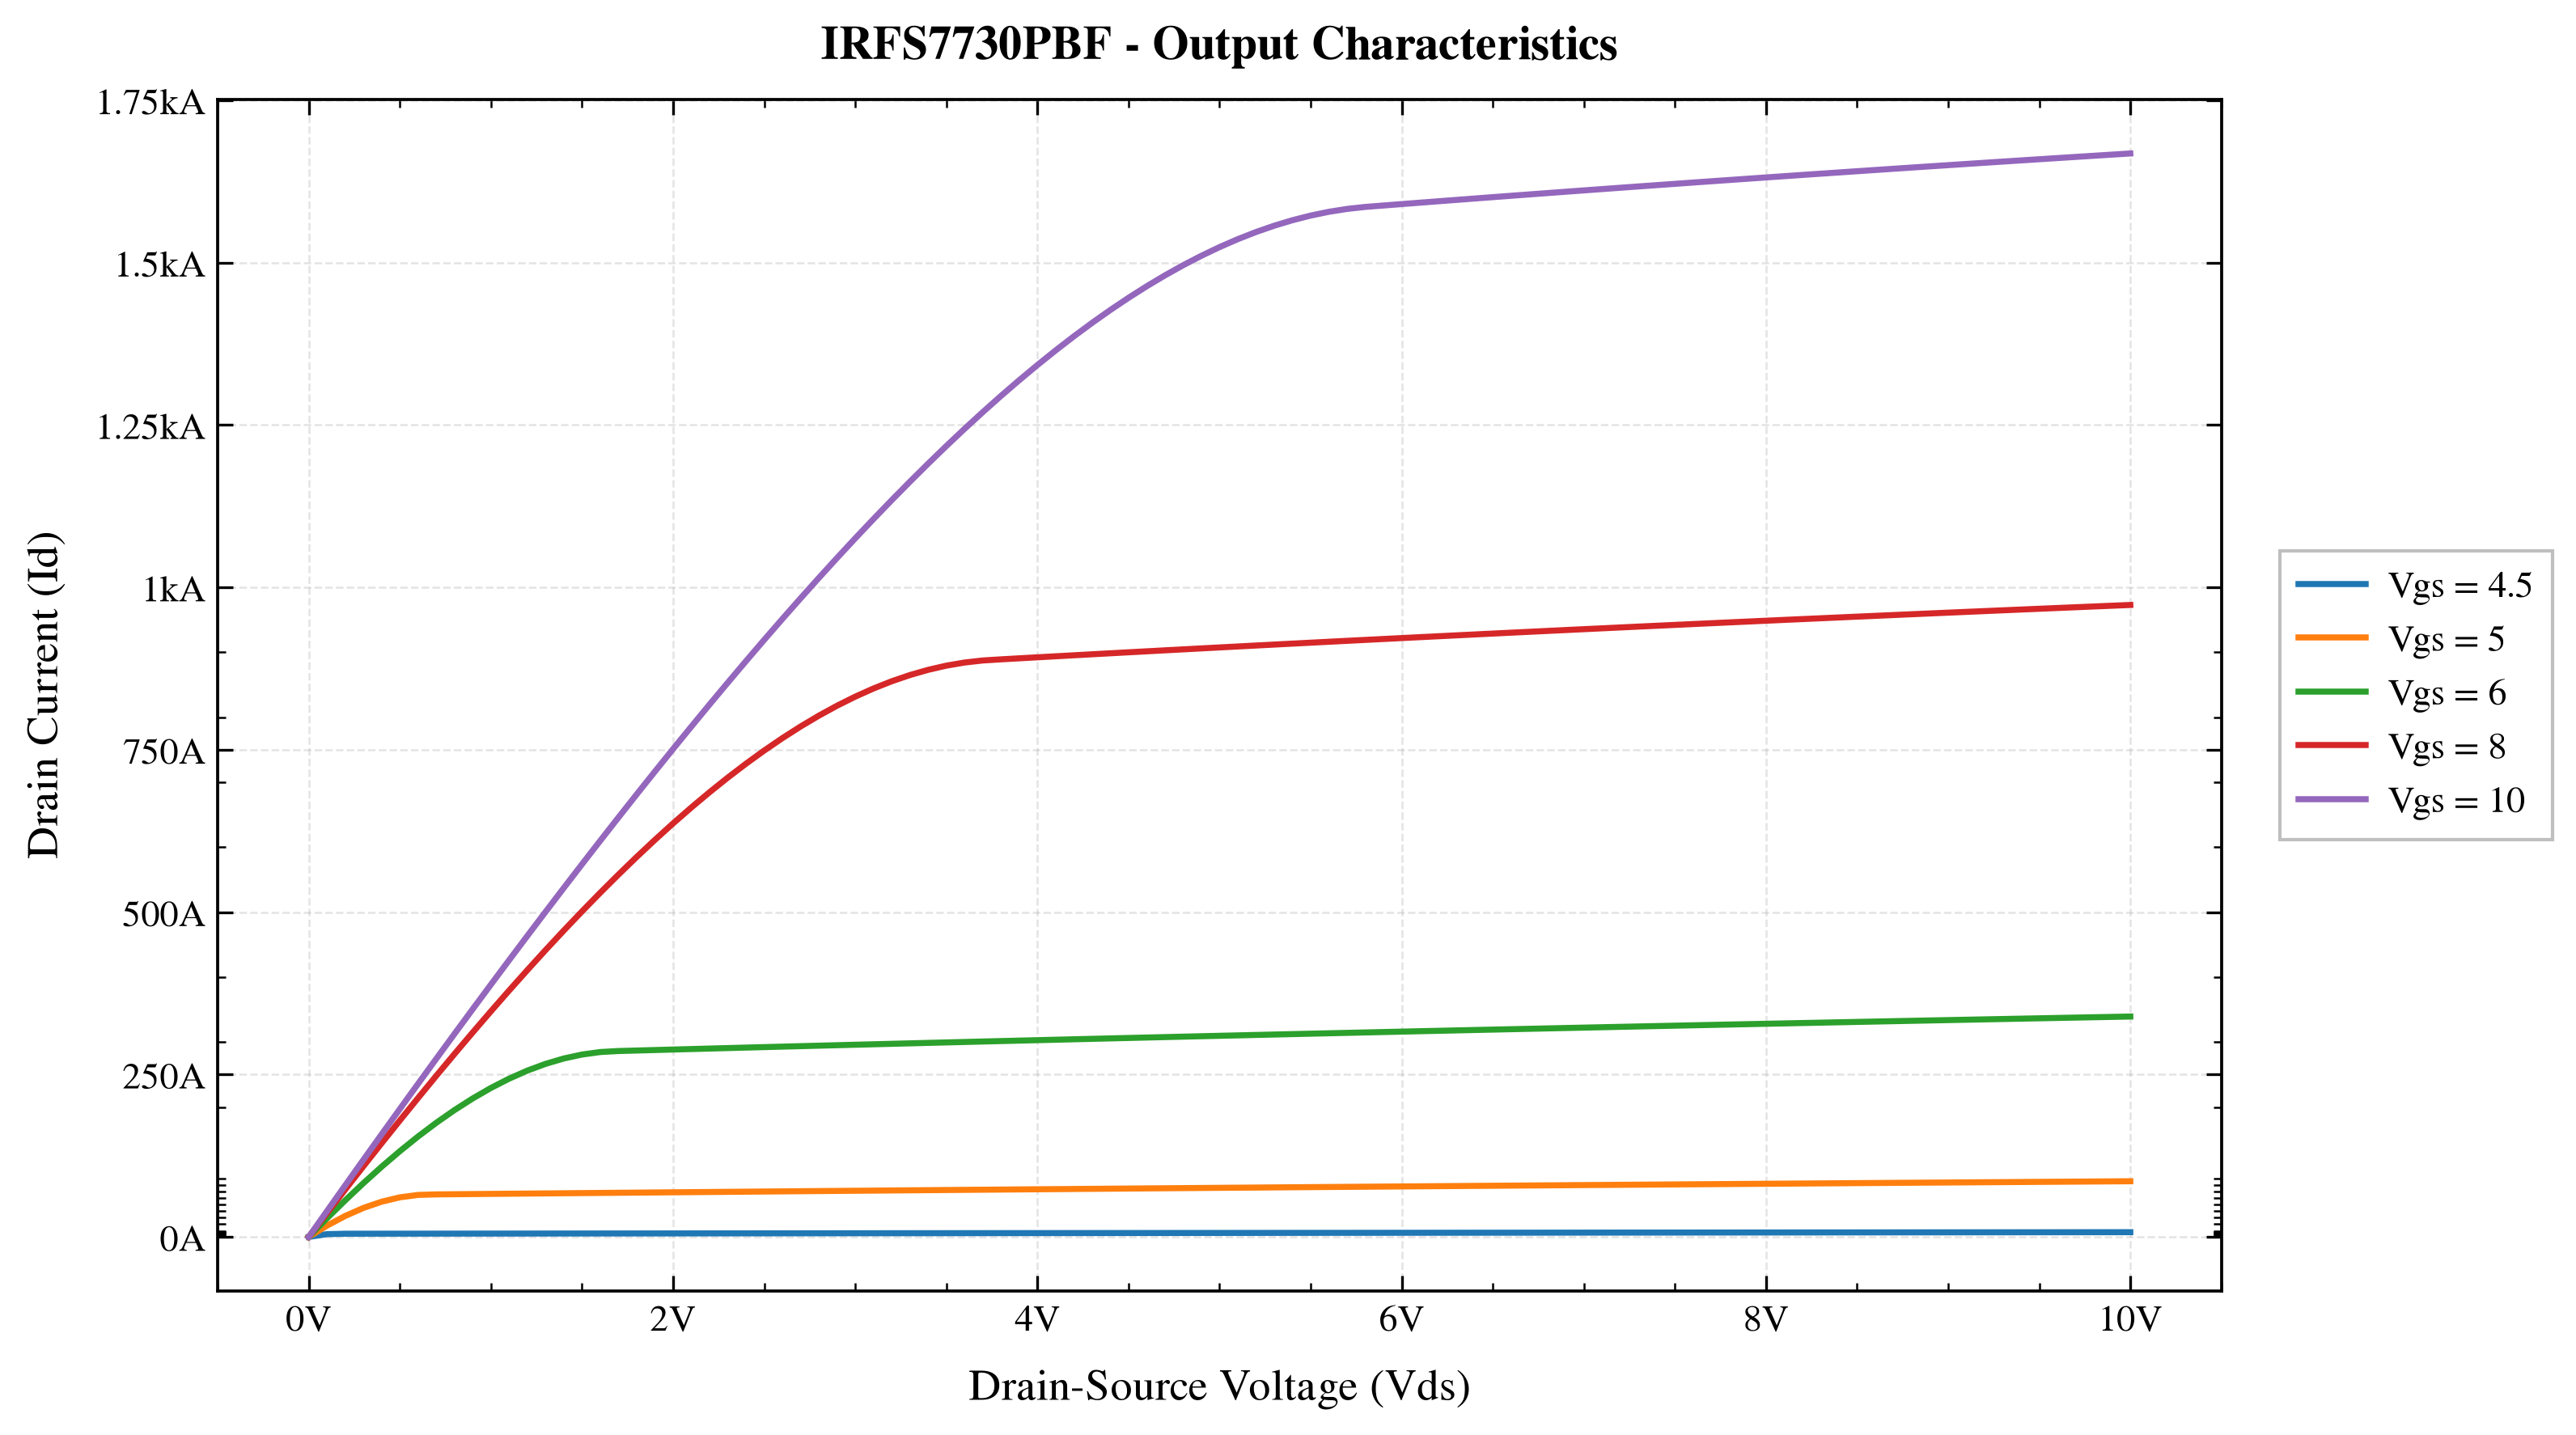

In [2]:
output_curves = static.run_output_characteristics(
    LIB, SUBCKT,
    vgs_list=[4.5, 5.0, 6.0, 8.0, 10.0],
    vds_max=10.0, vds_points=101,
)
fig1, ax1 = plot_curves(output_curves, f"{TITLE} - Output Characteristics")
plt.show()


## Study 2 - Transfer Characteristic (Id vs Vgs at Vds = 10 V)

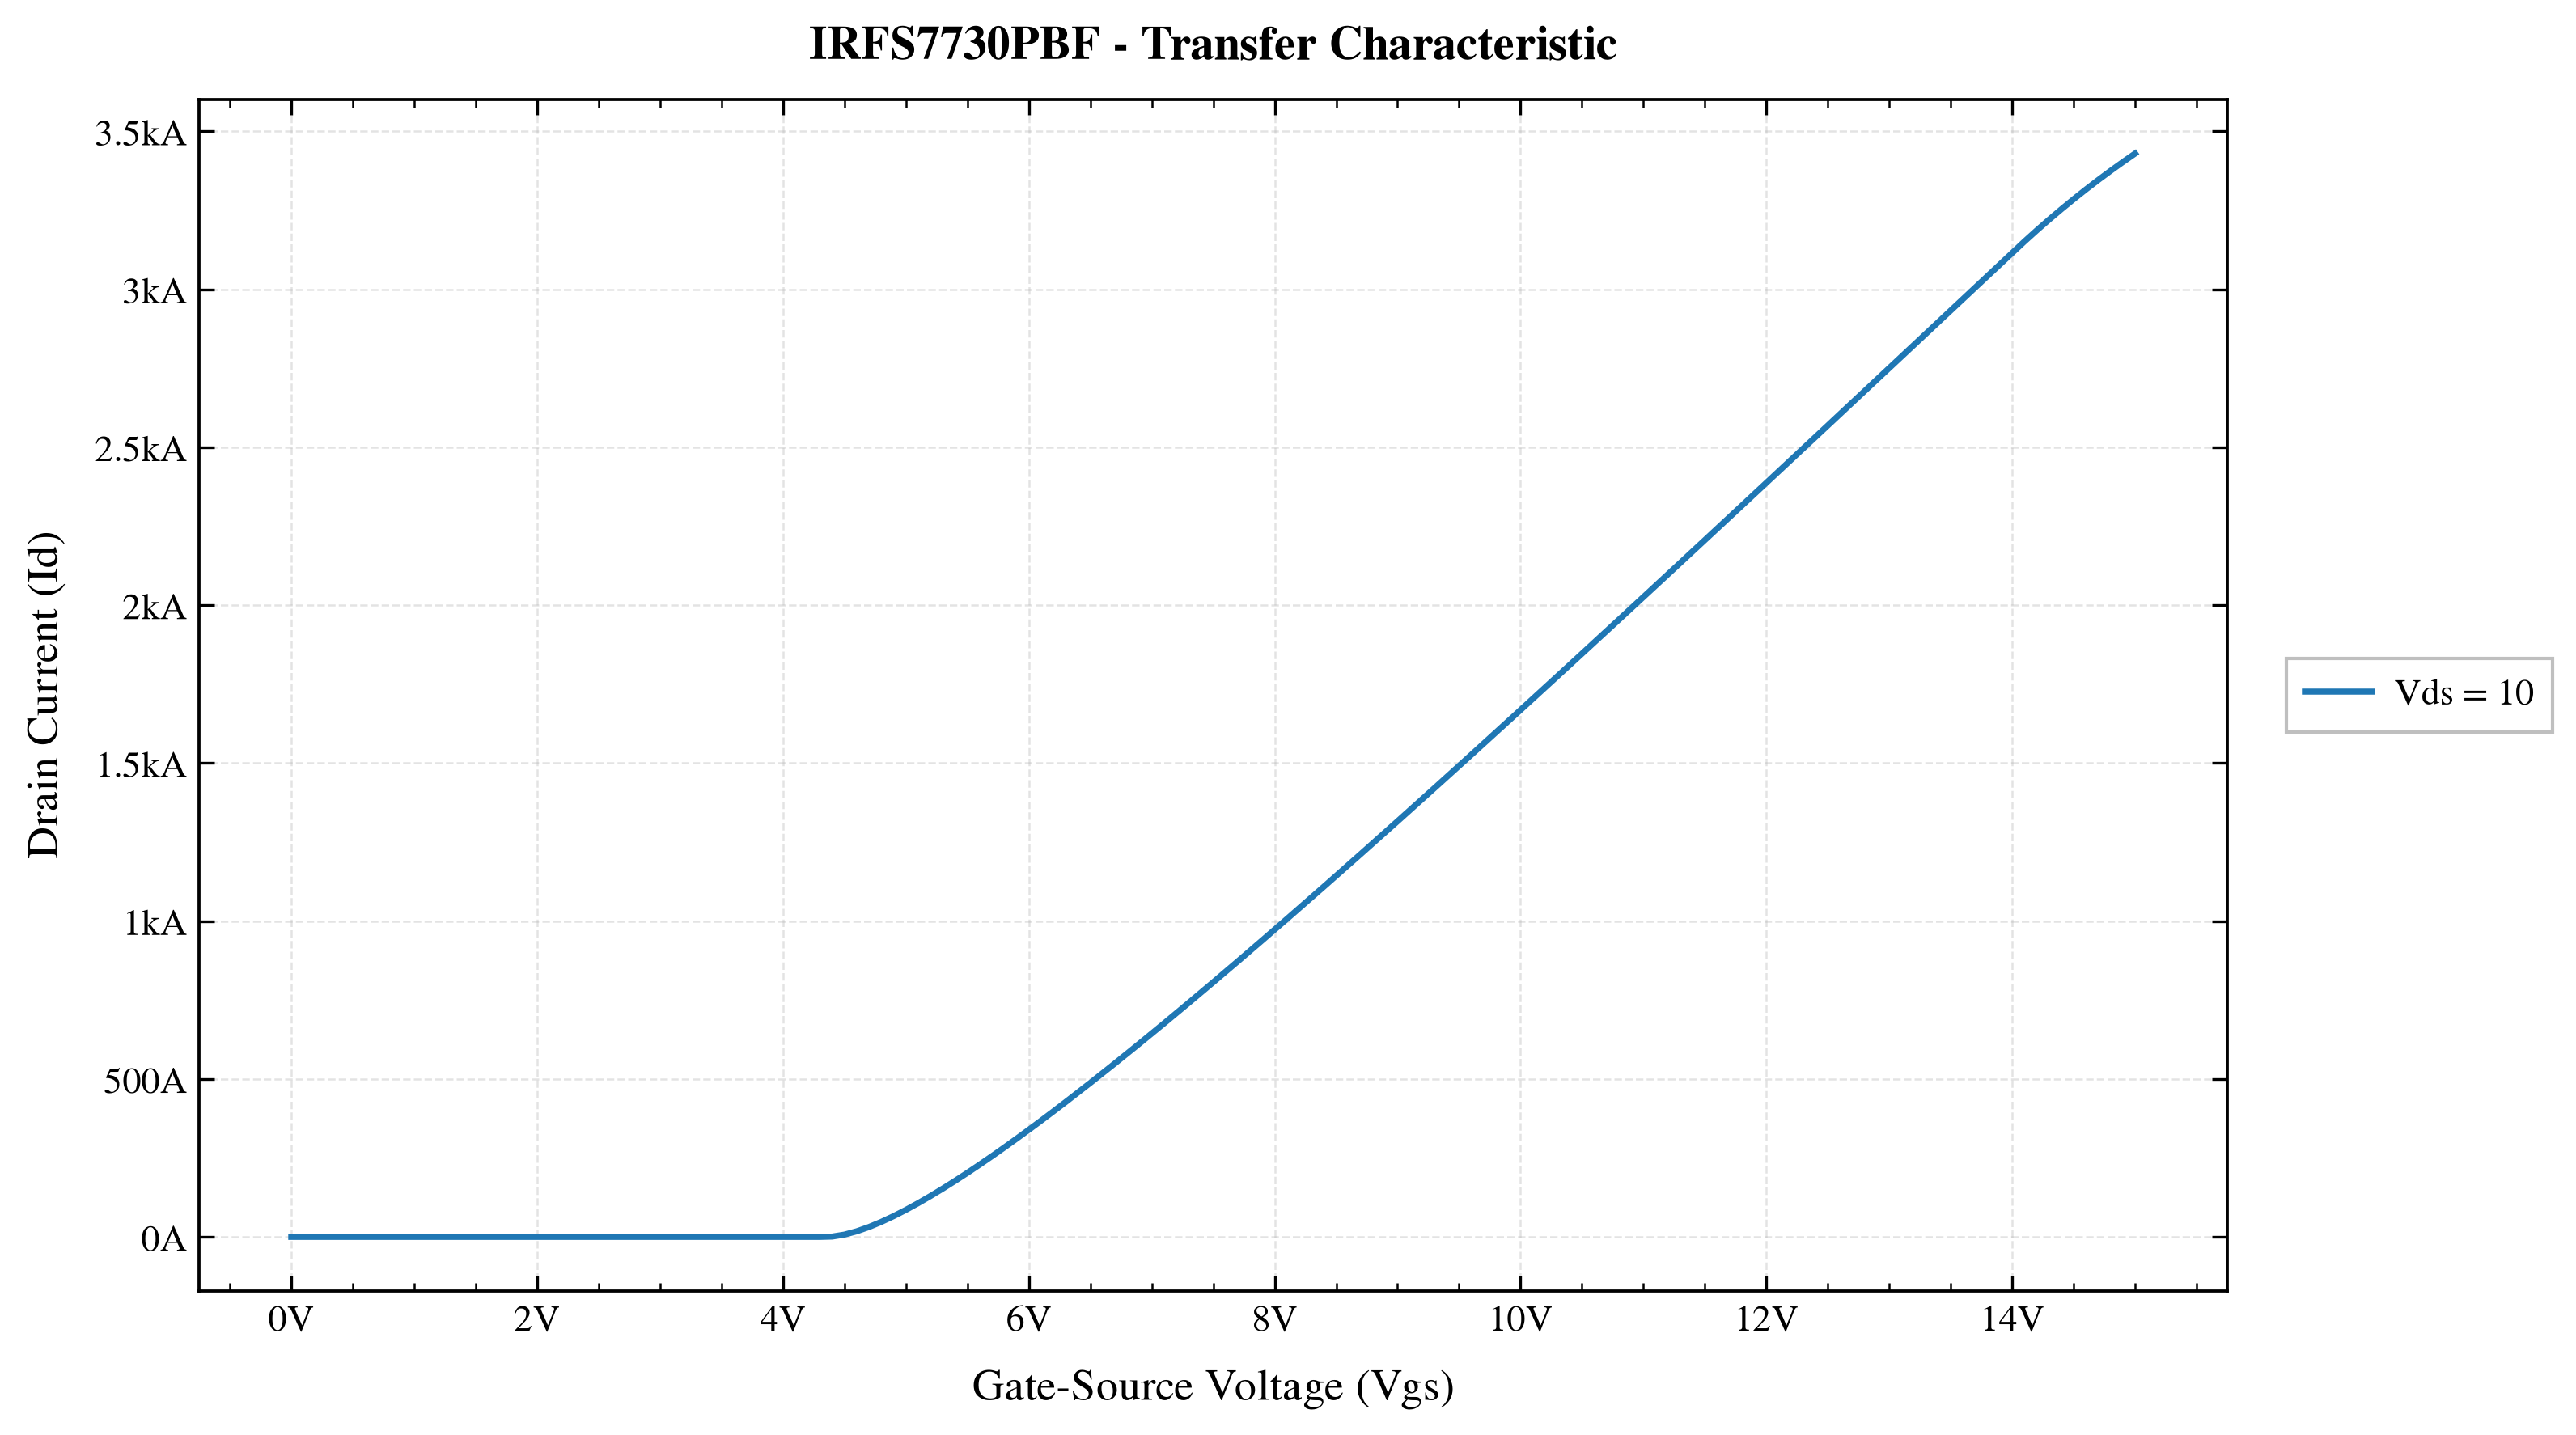

In [3]:
transfer_curve = static.run_transfer_characteristics(
    LIB, SUBCKT, vds_fixed=10.0, vgs_max=15.0, vgs_points=151,
)
fig2, ax2 = plot_curves([transfer_curve], f"{TITLE} - Transfer Characteristic")
plt.show()


## Study 3 - On-State Resistance (Rds(on) vs Id at Vgs = 10 V)

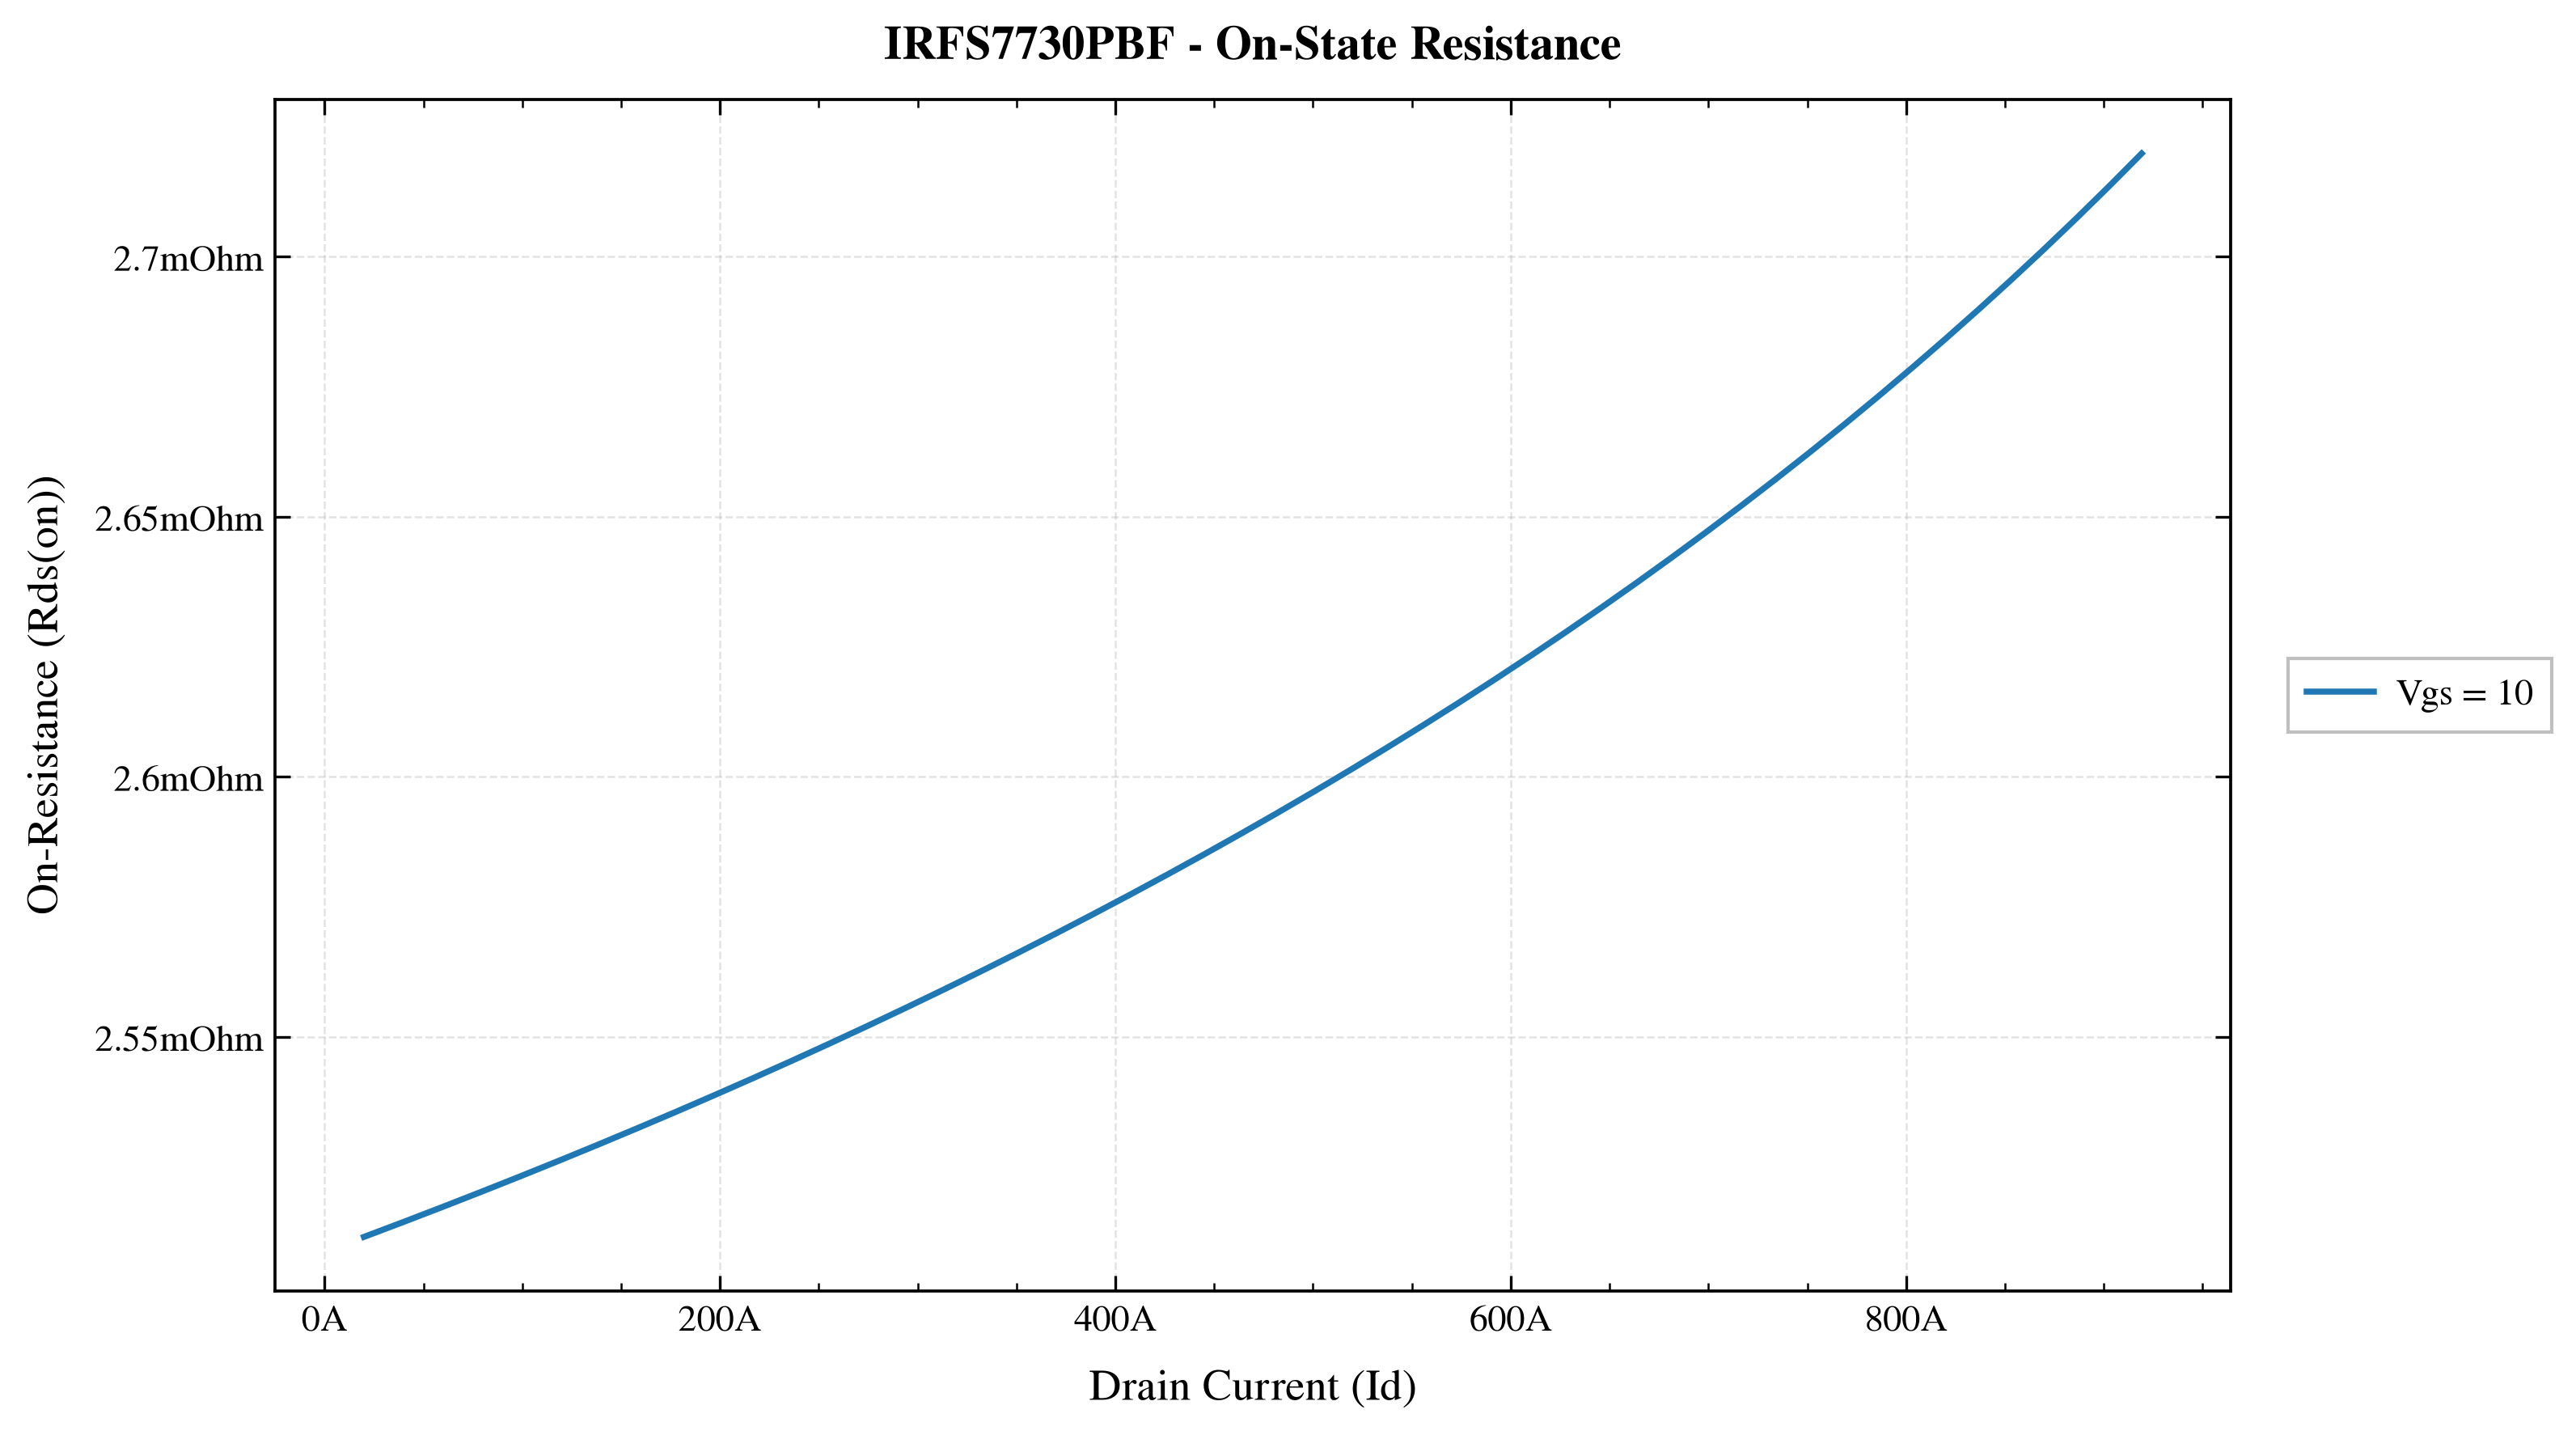

In [4]:
rds_curve = static.run_rds_on(LIB, SUBCKT, vgs=10.0, vds_max=2.5, vds_points=51)
fig3, ax3 = plot_curves([rds_curve], f"{TITLE} - On-State Resistance")
plt.show()


## Study 4 - Capacitances vs Vds
Small-signal AC method at 1 MHz; log sweep 0.1-60 V (model breakdown is 75 V).

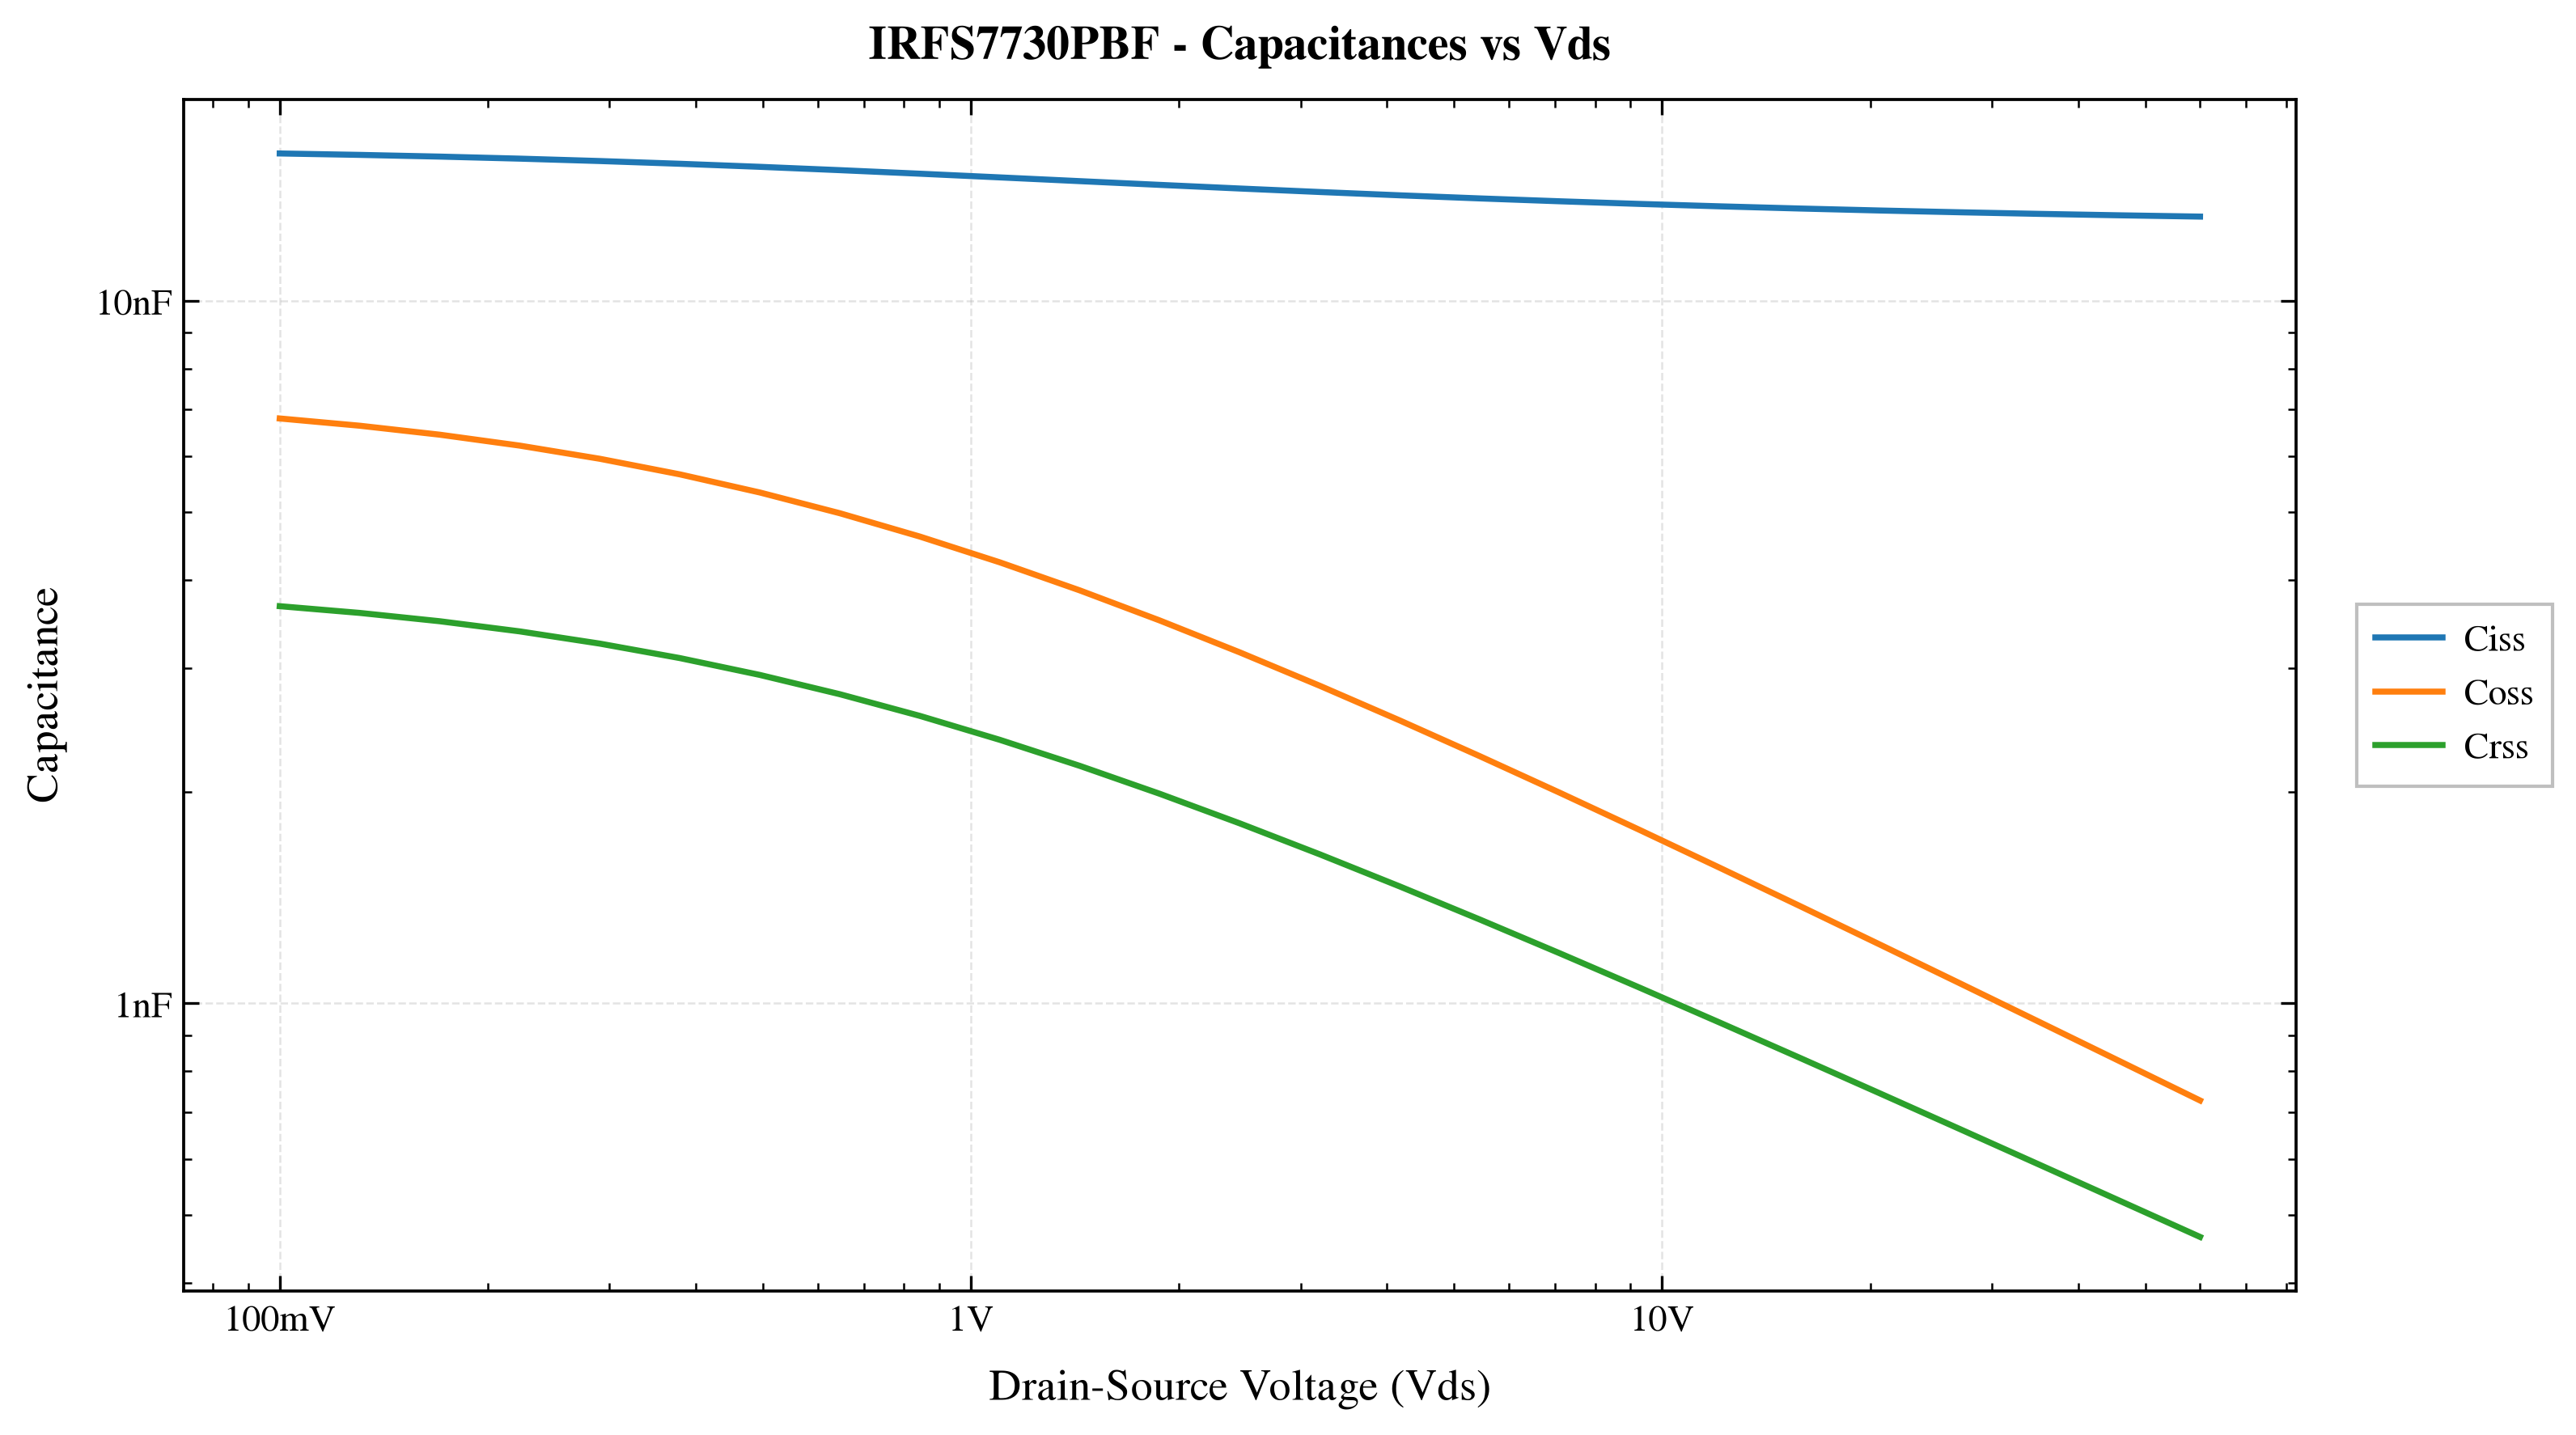

In [5]:
cap_curves = CapacitanceTestbench().run(LIB, SUBCKT, vds_min=0.1, vds_max=60.0, points=25)
fig4, ax4 = plot_curves(
    cap_curves, f"{TITLE} - Capacitances vs Vds", x_log=True, y_log=True,
    y_label="Capacitance",
)
plt.show()


## Study 5 - Gate Charge Curve (quasi-static reconstruction)

Three-segment model built from Study 2 (transfer) and Study 4 (capacitance) data at the
datasheet conditions **Id = 100 A, Vbus = 38 V**:

- **Segment 1 - Qgs**: integrate Ciss(Vds = Vbus) over Vgs from 0 to the plateau voltage
  (where Id(Vgs) crosses the load current).
- **Segment 2 - Qgd (Miller plateau)**: integrate Crss(Vds) over the drain swing Vbus -> ~0 V.
- **Segment 3 - tail**: integrate Ciss(low-Vds) from the plateau to Vgs = 10 V.

Datasheet reference values (typ): Qgs = 55 nC, Qgd = 79 nC, Qg = 271 nC. Deviations trace to the
vendor macromodel's LEVEL=1 core (no subthreshold conduction -> inflated effective threshold)
and its AC-calibrated-but-not-charge-accurate capacitance emulation; see `development-log.md`.


Plateau voltage Vgp : 5.07 V
Qgs                 : 67.3 nC   (datasheet typ 55)
Qgd (Miller)        : 36.0 nC   (datasheet typ 79)
Tail charge         : 79.9 nC
Total Qg @ Vgs=10V  : 183.2 nC   (datasheet typ 271)


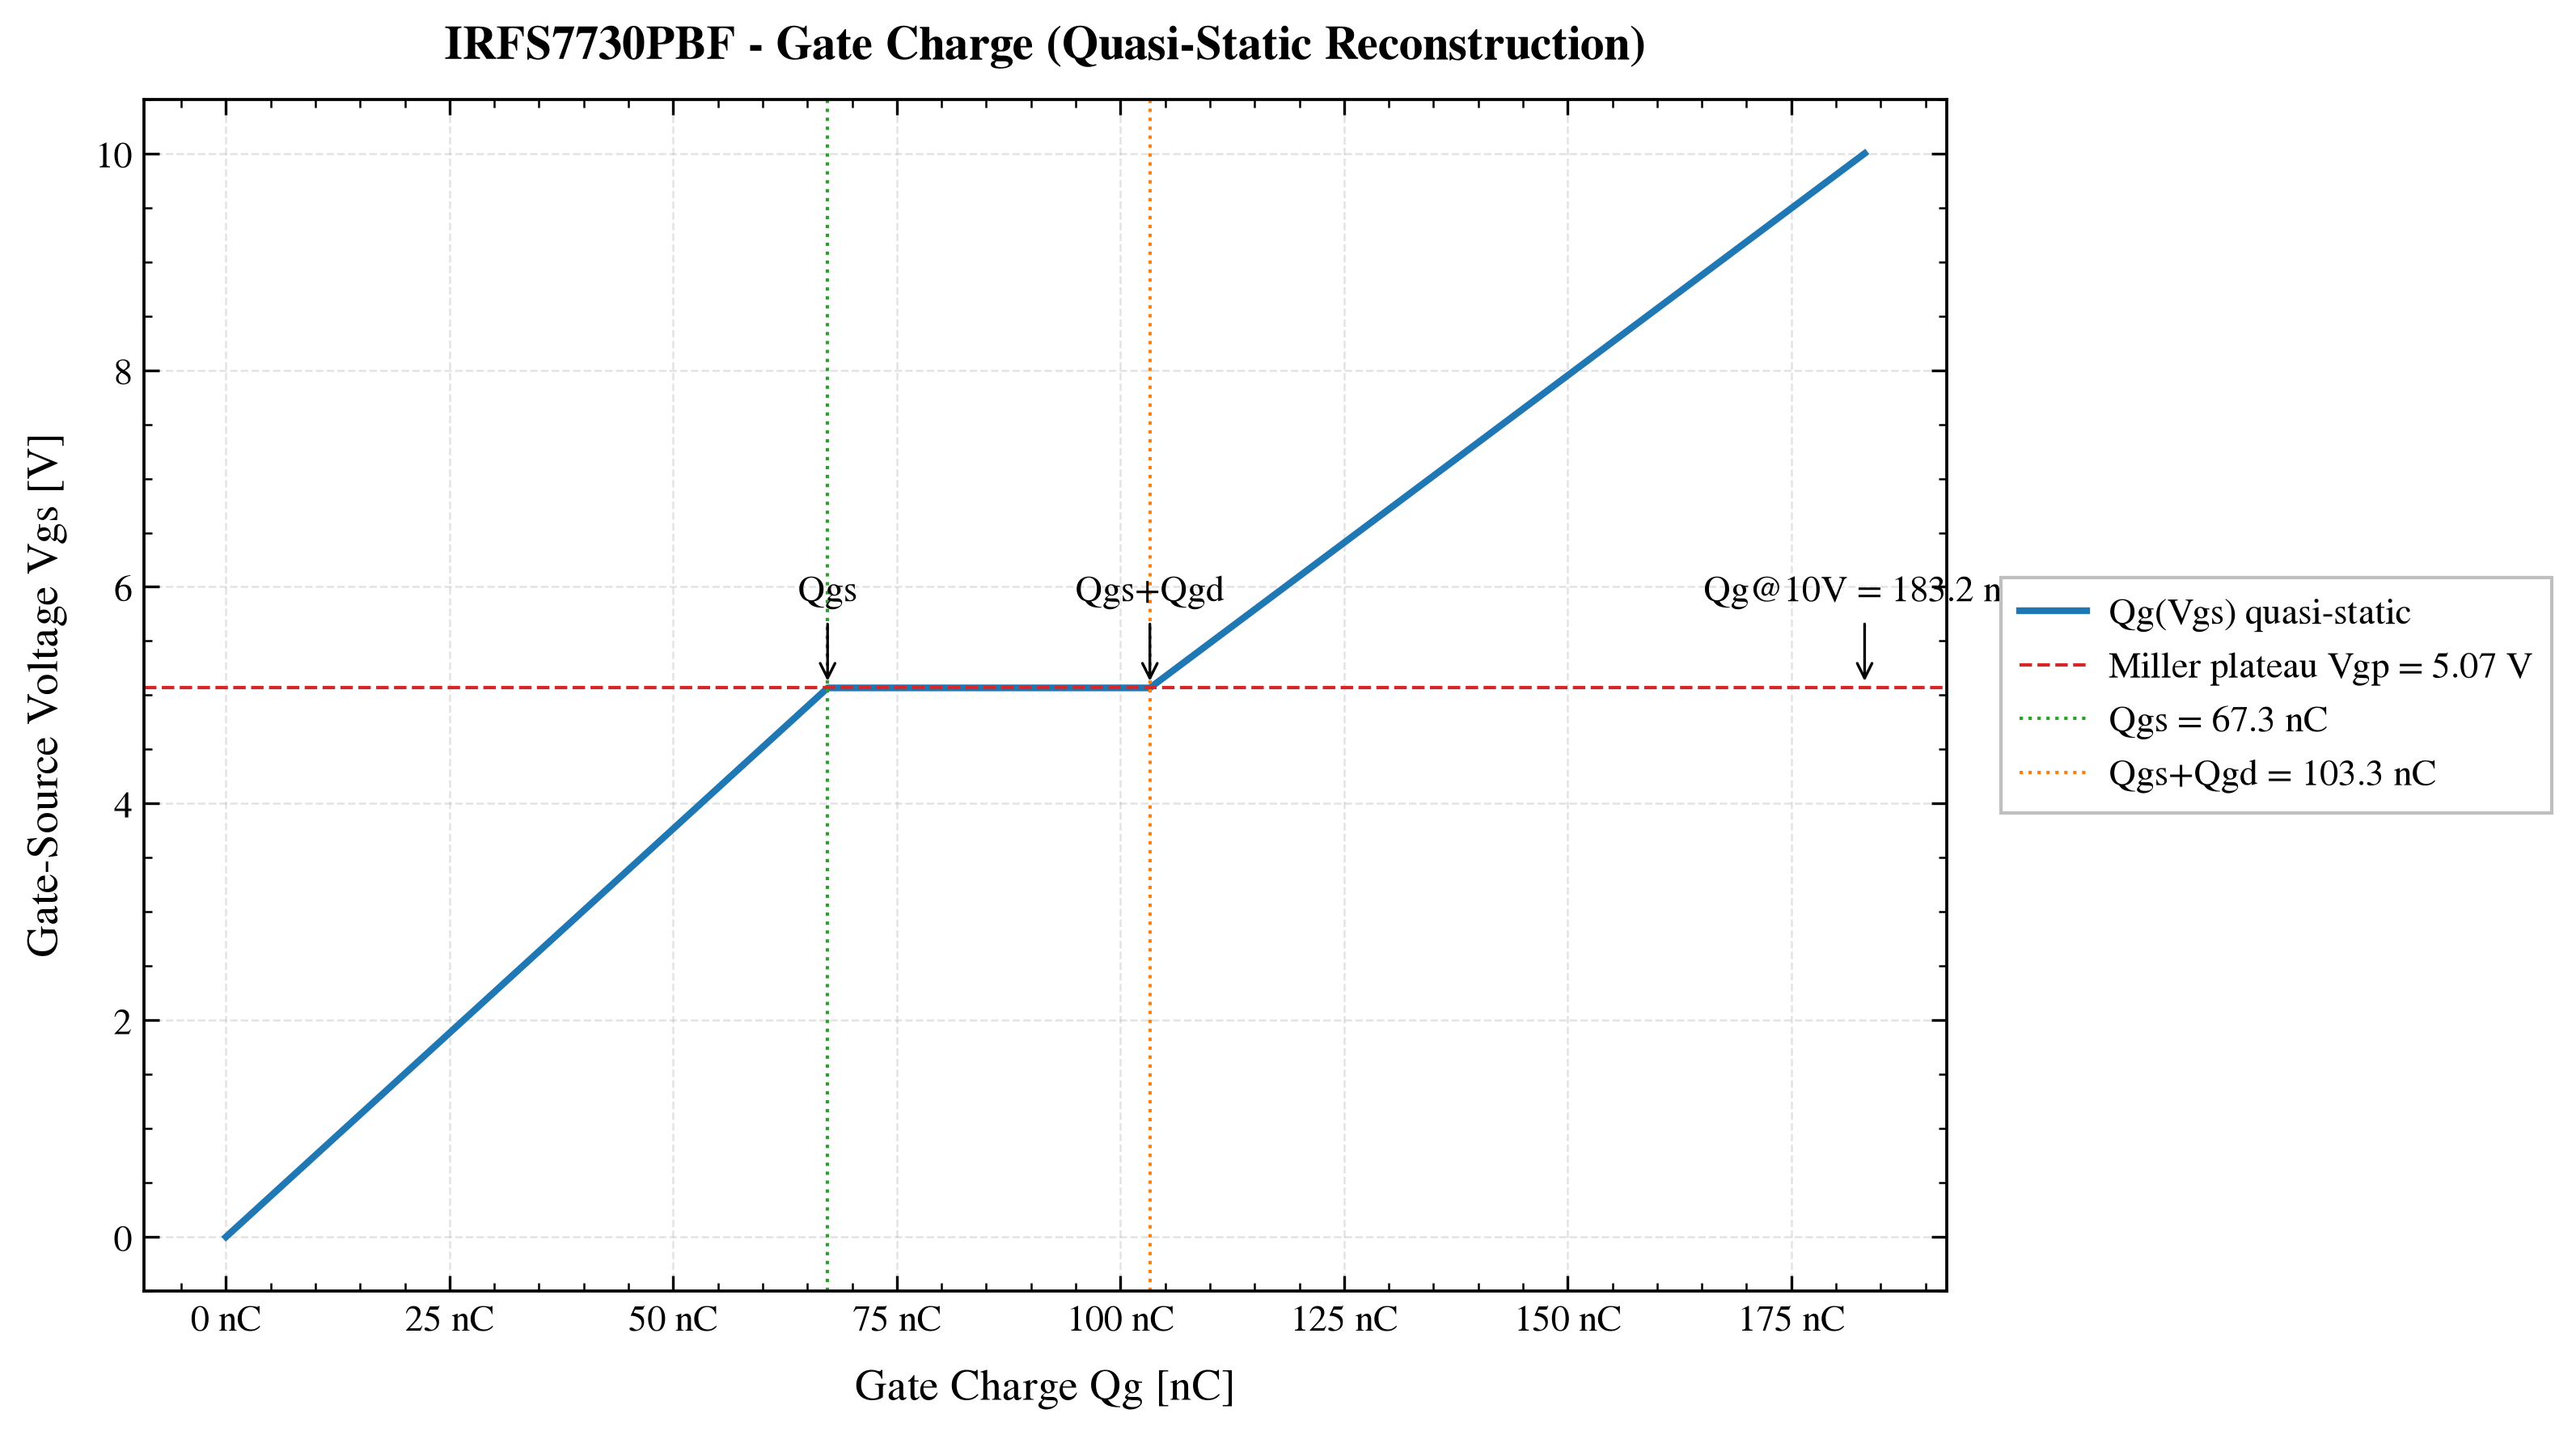

In [6]:
df_qg, bp = reconstruct_gate_charge(
    transfer_curve, cap_curves[0], cap_curves[2],
    v_bus=38.0, i_load=100.0, v_gs_max=10.0, v_ds_on=0.05,
)
print(f"Plateau voltage Vgp : {bp['v_plateau_V']:.2f} V")
print(f"Qgs                 : {bp['q_gs_nC']:.1f} nC   (datasheet typ 55)")
print(f"Qgd (Miller)        : {bp['q_gd_nC']:.1f} nC   (datasheet typ 79)")
print(f"Tail charge         : {bp['q_tail_nC']:.1f} nC")
print(f"Total Qg @ Vgs=10V  : {bp['q_total_nC']:.1f} nC   (datasheet typ 271)")

fig5, ax5 = plot_gate_charge(df_qg, bp)
ax5.set_title(f"{TITLE} - Gate Charge (Quasi-Static Reconstruction)")
plt.show()


## Study 6 - Body Diode Forward Characteristic (gate off)
Voltage-driven, capped at 1 V to stay clear of the diode exponential divergence.

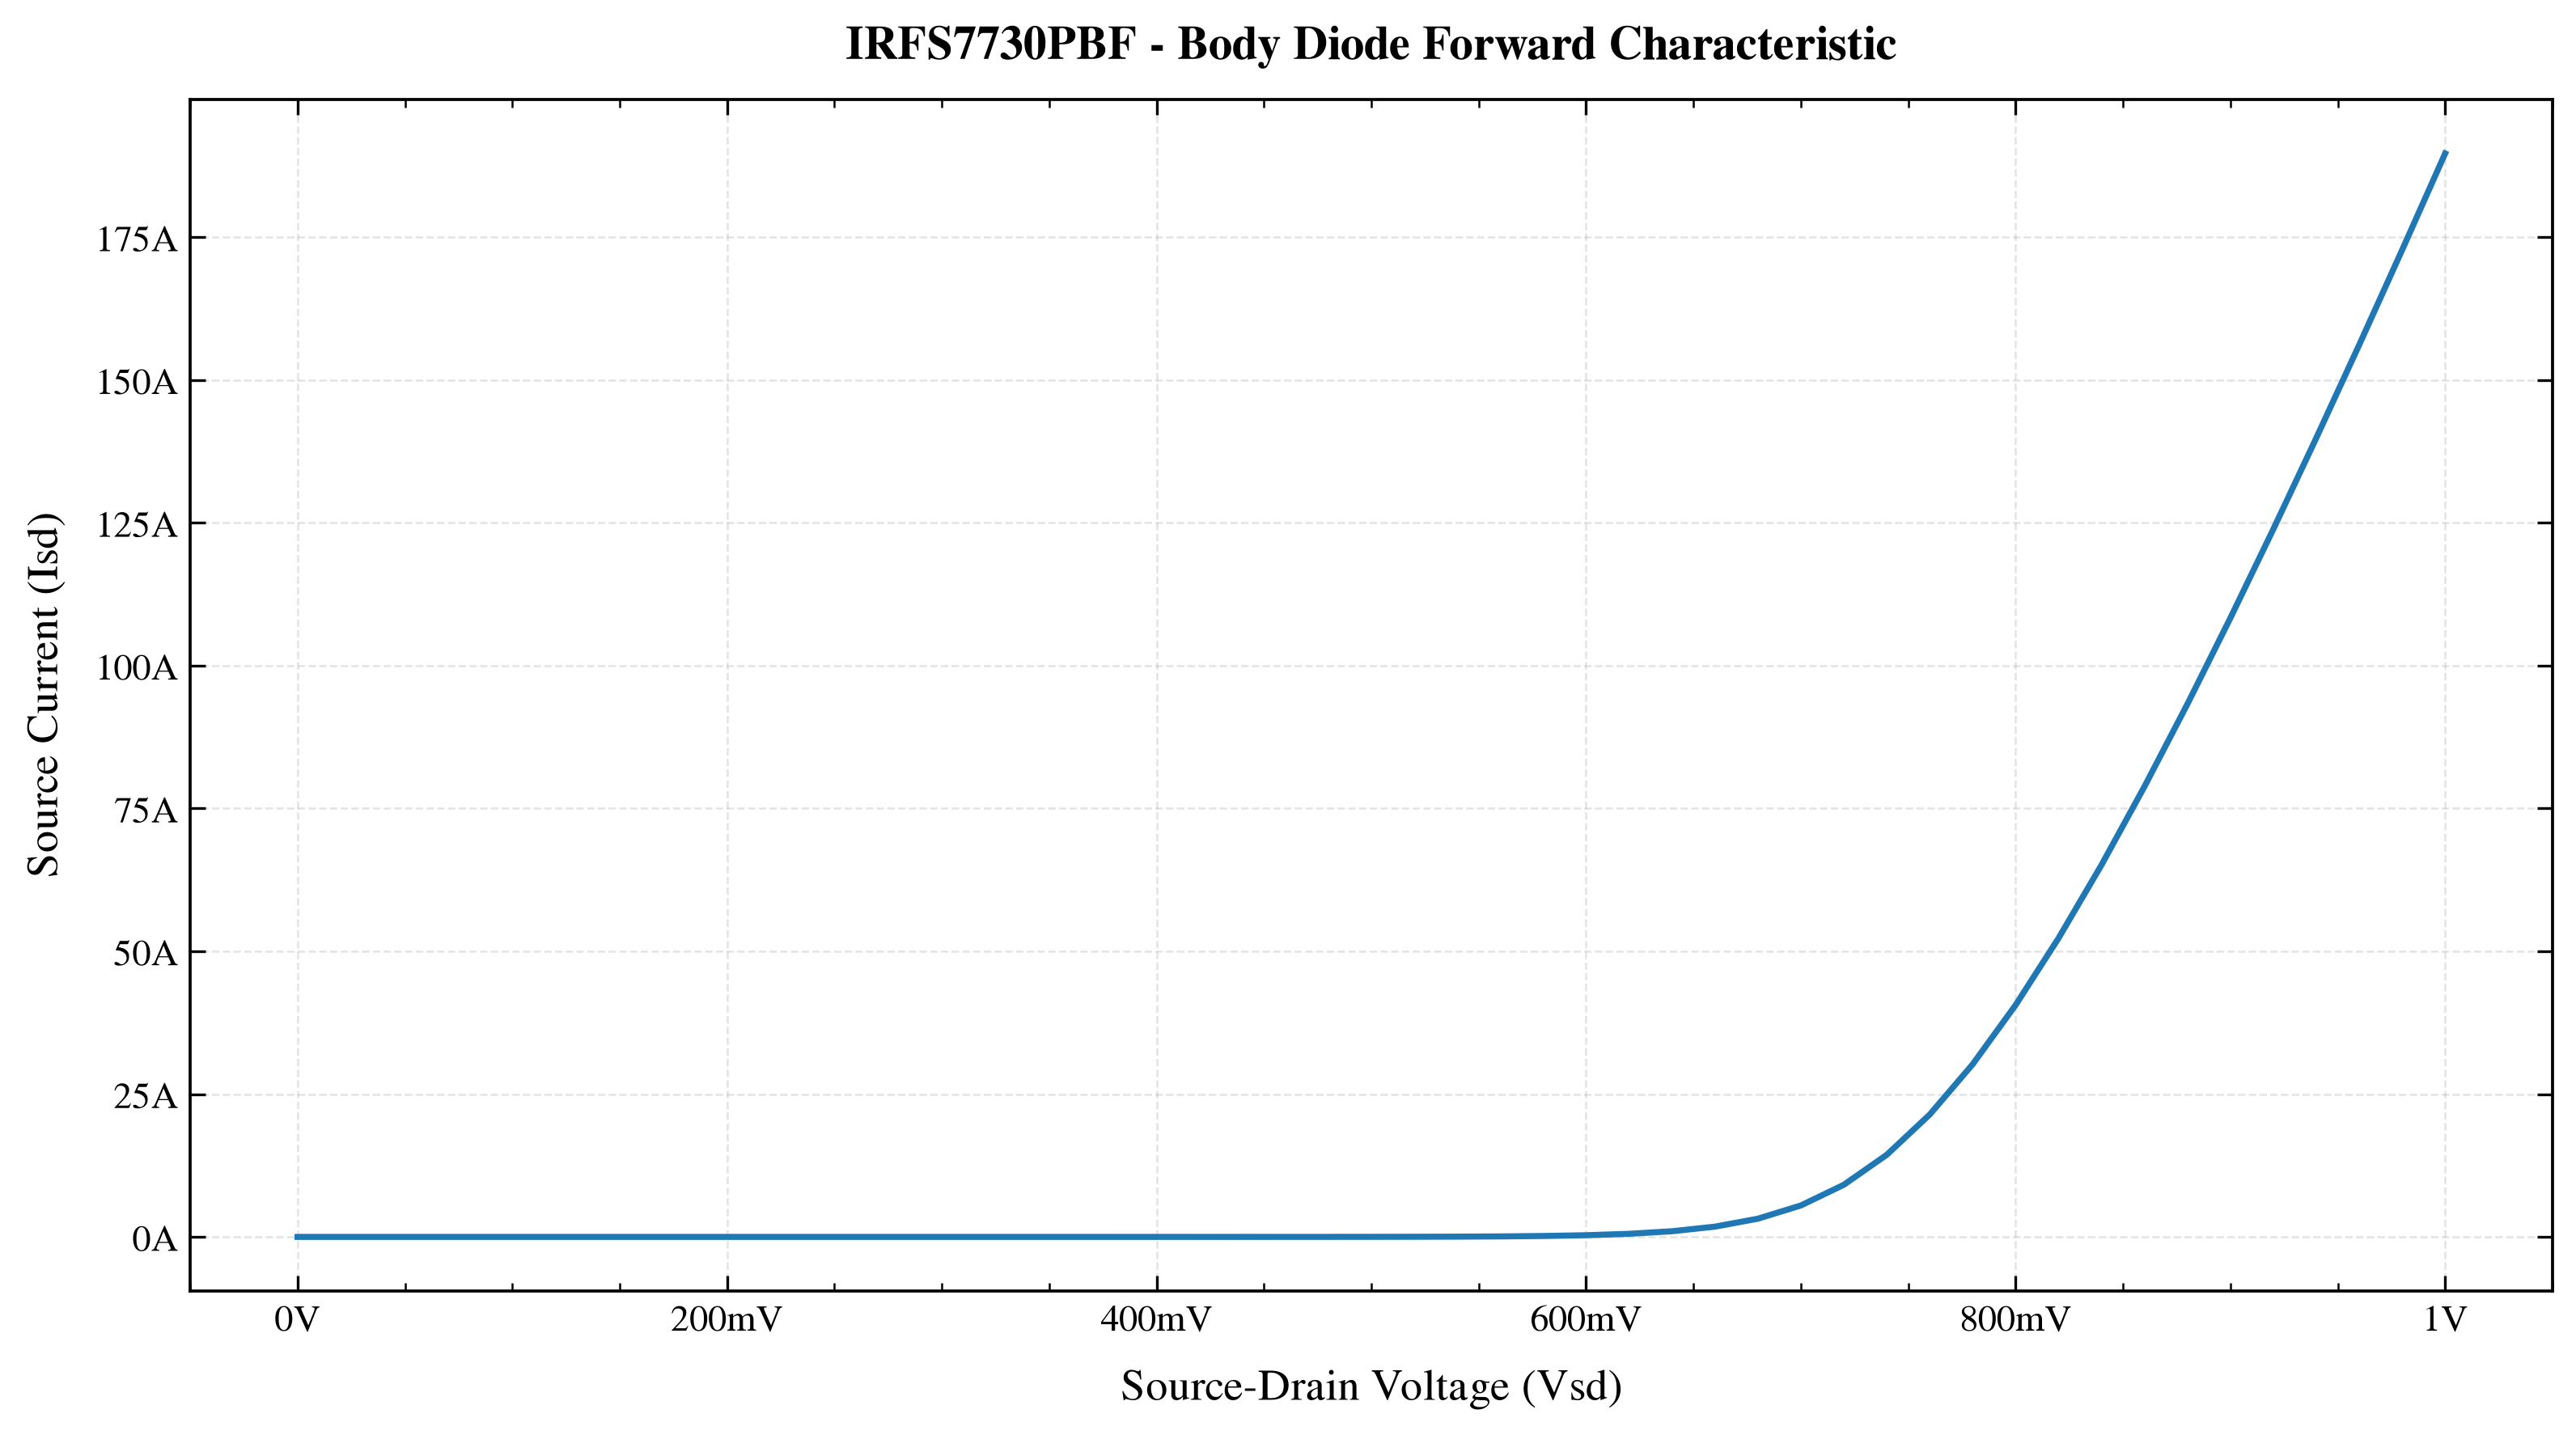

In [7]:
diode_curve = static.run_body_diode(LIB, SUBCKT, vsd_max=1.0, points=51)
fig6, ax6 = plot_curves([diode_curve], f"{TITLE} - Body Diode Forward Characteristic")
plt.show()


## Study 7 - Gate Threshold Voltage (constant-current method)

Datasheet convention: **gate shorted to drain (`Vds = Vgs`)**, sweep, interpolate
`Vgs` at **Id = 250 uA**.

> **Known model limitation:** this vendor macromodel uses a LEVEL=1 MOSFET with a hard
> threshold (no subthreshold conduction). The extracted value reflects the fitted
> `VTO = 4.346 V`, which matches the mid-current transfer characteristic but sits above
> the datasheet spec band **VGS(th) = 2.1-3.7 V** (`VDS = VGS, ID = 250 uA`). The real
> device's subthreshold physics cannot be represented by this LEVEL=1 model file; this is
> a vendor-model artifact, not an extraction error.


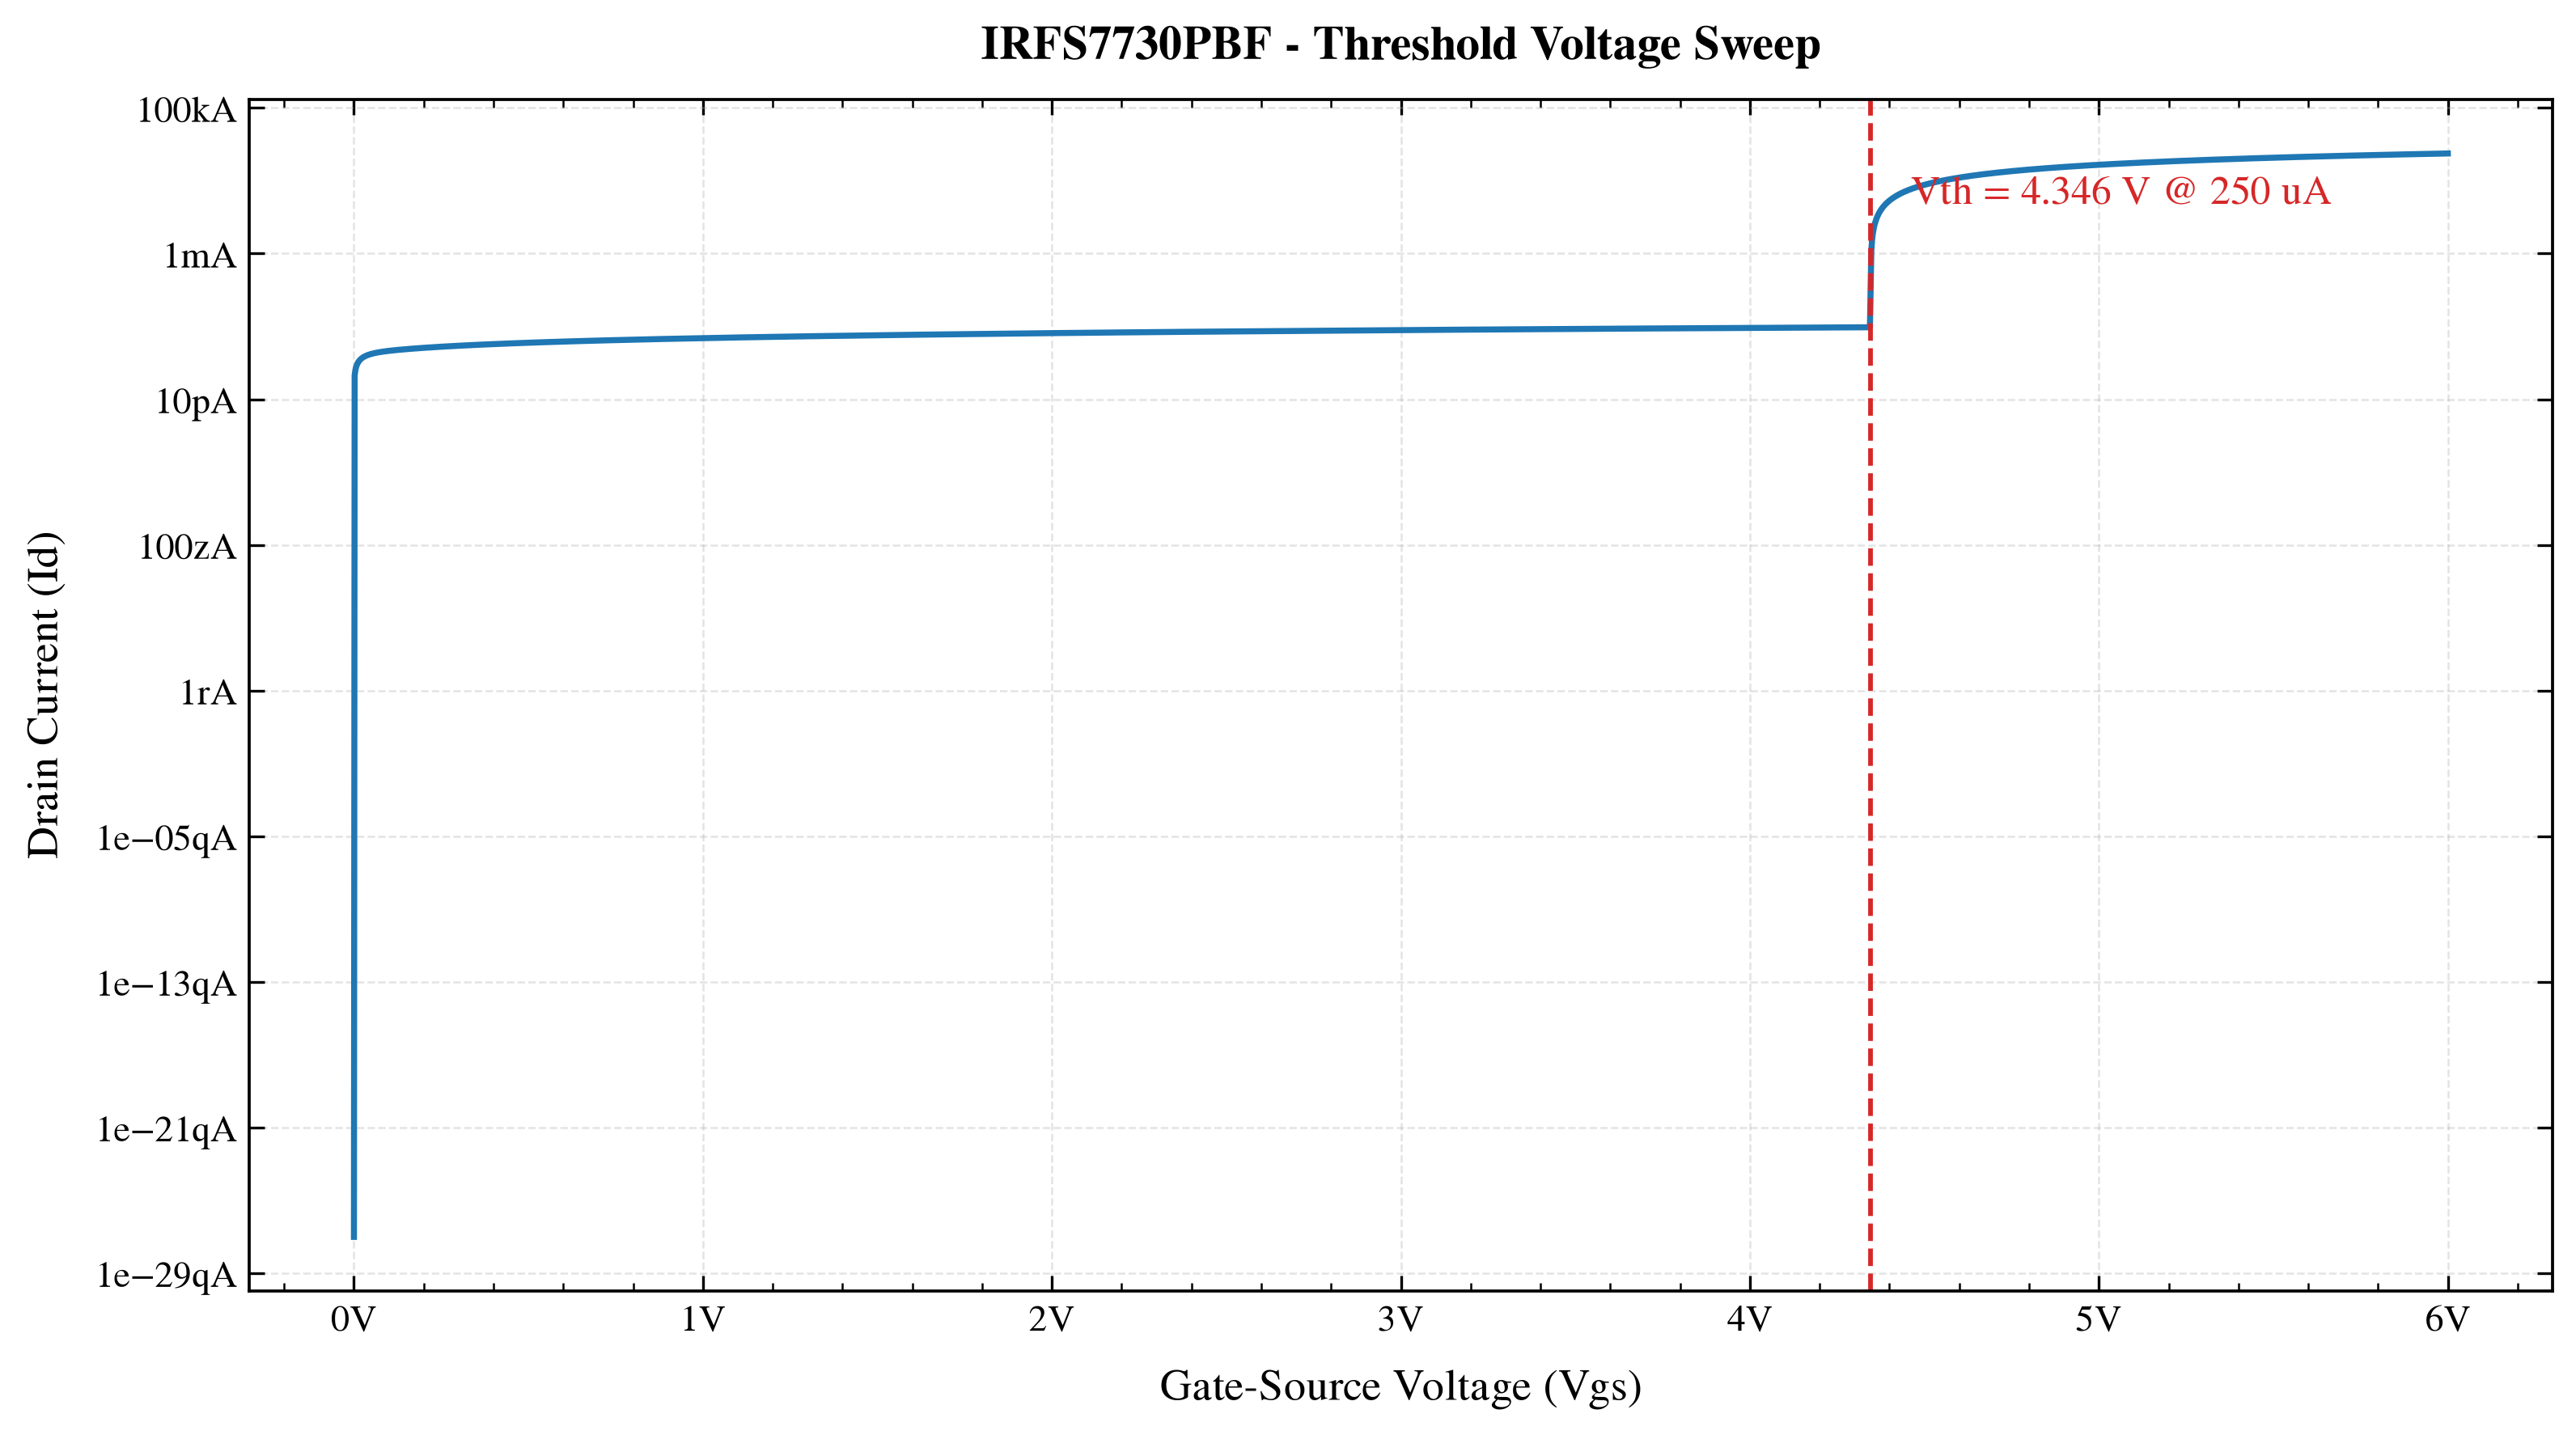

In [8]:
vth_curve, v_th = static.run_threshold_voltage(LIB, SUBCKT, i_target=250e-6, v_max=6.0)
fig7, ax7 = plot_curves([vth_curve], f"{TITLE} - Threshold Voltage Sweep", y_log=True)
ax7.axvline(v_th, color="tab:red", linestyle="--", linewidth=1.4)
ax7.annotate(
    f"Vth = {v_th:.3f} V @ 250 uA",
    xy=(v_th, 250e-6), xytext=(12, 18), textcoords="offset points",
    fontsize=12, color="tab:red",
)
plt.show()


## Extracted Datasheet Figures

In [9]:
rx, ry = rds_curve.to_numpy()

print(f"Rds(on) @ Vgs=10V, Id=50A : {np.interp(50.0, rx, ry):.2f} mOhm")
print(f"Vgs(th) constant-current  : {v_th:.3f} V   (model artifact, see note above)")
for c in cap_curves:
    print(f"{c.name} @ Vds=40V            : {np.interp(40.0, c.x_data, c.y_data) * 1e9:.2f} nF")
dx, dy = diode_curve.to_numpy()
print(f"Body diode Vsd @ Isd=50A  : {np.interp(50.0, dy, dx) * 1e3:.1f} mV")
print(f"Gate charge Qg @ 10V      : {bp['q_total_nC']:.1f} nC  (quasi-static reconstruction)")


Rds(on) @ Vgs=10V, Id=50A : 2.52 mOhm
Vgs(th) constant-current  : 4.346 V   (model artifact, see note above)
Ciss @ Vds=40V            : 13.26 nF
Coss @ Vds=40V            : 0.89 nF
Crss @ Vds=40V            : 0.56 nF
Body diode Vsd @ Isd=50A  : 816.1 mV
Gate charge Qg @ 10V      : 183.2 nC  (quasi-static reconstruction)
